# Reinforcement learning

Thư viện muốn một robot chuyển sách từ cửa vào tới bàn trả sách. Trên bản đồ có một ô bị chắn; lệnh nào đưa robot vào tường hay vào ô chắn thì robot đứng yên, nhưng vẫn mất một lượt. Nếu biết toàn bộ bản đồ và quy tắc, có thể dùng BFS. Bây giờ giả sử chương trình điều khiển chỉ được gửi một hành động, nhìn vị trí mới và nhận một điểm thưởng. Sau nhiều lần đi, nó phải tự chọn hành động tốt. Làm thế nào để một bước ở xa đích vẫn được đánh giá là có ích?

Reinforcement learning (học tăng cường) học cách hành động từ tương tác và phần thưởng. Câu hỏi xuyên suốt bài là: **robot đang cải thiện điều gì sau mỗi lần thử?** Một chương trình chỉ bốc hướng ngẫu nhiên mà không lưu và cập nhật kiến thức vẫn chưa học được policy.

> **Mục tiêu sau bài này**
>
> - Viết trạng thái, hành động, chuyển trạng thái, phần thưởng và điều kiện kết thúc của một MDP nhỏ.
> - Tính return và một bước Bellman; phân biệt planning bằng mô hình đã biết với học từ trải nghiệm.
> - Cài Q-learning, kiểm riêng bước terminal và đánh giá policy đã học bằng một đường đi thật.
> - Giải thích policy gradient trên một bài toán một bước, rồi mở rộng sang episode nhiều bước với return từng thời điểm và baseline.

## Từ hành động tới một vòng tương tác

Ở thời điểm $t$, agent nhìn trạng thái $S_t$, chọn hành động $A_t$. Environment thực hiện hành động và trả về phần thưởng $R_{t+1}$ cùng trạng thái $S_{t+1}$. Chỉ số $t+1$ nhắc rằng phần thưởng là kết quả **sau** hành động; nó không phải nhãn đúng của hành động được đưa sẵn trước khi chọn. Học từ thưởng qua tương tác như vậy là học tăng cường (reinforcement learning): chương trình tự chơi game, được cộng điểm khi thắng, hay hệ thống điều khiển đèn giao thông để xe chạy thông suốt.



Một policy, ký hiệu $\pi(a\mid s)$, cho xác suất chọn hành động $a$ khi ở trạng thái $s$. Policy có thể tất định, như luôn đi phải ở một ô; cũng có thể ngẫu nhiên, như đi phải với xác suất $0.7$. Phần thưởng nói mục tiêu cần đạt, còn policy nói cách thực hiện. Ta thường chưa biết hành động tốt nhất để đưa làm nhãn huấn luyện.

Muốn vị trí ô đủ mô tả trạng thái, kết quả bước tiếp theo chỉ được phụ thuộc vào vị trí và hành động hiện tại, không cần toàn bộ lịch sử. Đó là tính Markov. Nếu robot còn pin và pin ảnh hưởng khả năng di chuyển, phải thêm mức pin vào trạng thái. Nếu nhiệm vụ bắt buộc kết thúc sau đúng 20 lượt, thời gian còn lại cũng có thể ảnh hưởng quyết định và phải được biểu diễn. Bỏ một biến cần thiết khiến cùng một “trạng thái” có hai cách diễn biến khác nhau.

**Hỏi nhanh.** Robot chỉ ghi lại vị trí ô. Khi pin yếu, lệnh “tiến” có lúc không làm robot di chuyển. Nên sửa mô tả trạng thái thế nào?

- A. Đổi seed mỗi episode để trung bình hóa ảnh hưởng của pin
- B. Thêm mức pin hiện tại vào trạng thái
- C. Đưa toàn bộ chuỗi ô đã đi qua vào trạng thái
- D. Giữ nguyên vị trí, chỉ tăng số episode để có đủ mẫu

<details><summary>Đáp án</summary>

B. Thêm mức pin hiện tại vào trạng thái

Hai robot cùng ô nhưng pin khác nhau cho kết quả khác nhau với cùng một hành động, nên vị trí chưa đủ để có tính Markov. Thêm mức pin là sửa đúng chỗ còn thiếu. Chuỗi ô đã đi chỉ gợi ý gián tiếp lượng pin đã tiêu, mà làm số trạng thái phình lên rất nhanh. Đổi seed hay thêm episode không thay đổi được việc cùng một “trạng thái” có hai cách diễn biến. Agent khi ấy chỉ học được trung bình của hai trường hợp.

</details>

## Đặt một MDP đủ nhỏ để kiểm bằng tay

Markov decision process (MDP) gồm tập trạng thái $\mathcal S$, tập hành động $\mathcal A$, quy luật chuyển và thưởng $p(s',r\mid s,a)$, cùng hệ số chiết khấu $\gamma$. Ta dùng lưới 3 hàng, 4 cột; tọa độ viết `(hàng, cột)`, bắt đầu từ 0 ở góc trên trái. Robot xuất phát ở $(2,0)$, đích ở $(0,3)$, ô $(1,1)$ bị chắn. Mỗi ô còn lại là một trạng thái, nên có 11 trạng thái.



Bốn hành động là lên, xuống, trái, phải. Va tường hoặc đi ra ngoài lưới thì giữ nguyên vị trí. Mỗi bước chưa vào đích nhận $-1$ điểm; bước vào đích nhận $10$ điểm và kết thúc episode, tức một lần thực hiện nhiệm vụ. Đích không còn hành động cần học. Chuyển trạng thái ở đây tất định; xác suất của kết quả đúng bằng 1. Trong môi trường có trượt chân, cùng một hành động có thể dẫn tới nhiều kết quả và ta phải lấy kỳ vọng theo $p$.

Ta cài environment trước, rồi kiểm hai trường hợp dễ nhầm: va ô chắn và vào đích. Toàn bộ code trong bài chạy nối tiếp; chỉ cần NumPy.

In [ ]:
import numpy as np

states = [(r, c) for r in range(3) for c in range(4) if (r, c) != (1, 1)]
state_id = {cell: i for i, cell in enumerate(states)}
start, goal = state_id[(2, 0)], state_id[(0, 3)]
moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]
action_names = ["U", "D", "L", "R"]
gamma = 0.9

def step(state, action):
    assert state != goal, "Không bước tiếp sau khi đã tới đích."
    row, col = states[state]
    dr, dc = moves[action]
    next_cell = (row + dr, col + dc)
    next_state = state_id.get(next_cell, state)
    terminated = next_state == goal
    reward = 10.0 if terminated else -1.0
    return next_state, reward, terminated

wall_step = step(state_id[(1, 0)], 3)
goal_step = step(state_id[(0, 2)], 3)
assert wall_step == (state_id[(1, 0)], -1.0, False)
assert goal_step == (goal, 10.0, True)
print("Số trạng thái:", len(states))
print("Va ô chắn:", states[wall_step[0]], wall_step[1:])
print("Vào đích:", states[goal_step[0]], goal_step[1:])

Số trạng thái: 11
Va ô chắn: (1, 0) (-1.0, False)
Vào đích: (0, 3) (10.0, True)


Dòng va ô chắn phải giữ vị trí cũ và vẫn trừ một điểm. Dòng vào đích phải có `True`; nếu quên điều kiện ấy, robot có thể tiếp tục thu thưởng hoặc bị phạt sau khi nhiệm vụ đã xong.

**Hỏi nhanh.** Đổi luật chơi: robot có hướng nhìn là N, E, S hoặc W, và chỉ còn ba hành động là quay trái, quay phải, và tiến một ô theo hướng đang nhìn. Trên lưới của bài, MDP mới có bao nhiêu trạng thái và bao nhiêu hành động?

- A. 11 trạng thái, 3 hành động
- B. 48 trạng thái, 3 hành động
- C. 44 trạng thái, 4 hành động
- D. 44 trạng thái, 3 hành động

<details><summary>Đáp án</summary>

D. 44 trạng thái, 3 hành động

Kết quả của lệnh tiến phụ thuộc hướng đang nhìn, nên hướng phải nằm trong trạng thái: 11 ô nhân 4 hướng, tức $11\times 4 = 44$. Ô bị chắn không phải trạng thái, nên không phải $12\times 4 = 48$. Hướng là một phần của trạng thái chứ không phải hành động, và tập hành động chỉ có ba lệnh. Giữ 11 trạng thái thì cùng một “trạng thái” có bốn kết quả khác nhau cho lệnh tiến.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q3.1](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=15)

</details>

## Vì sao nhìn thưởng một bước chưa đủ?

Một bước xa đích chỉ có thưởng $-1$, dù nó mở đường tới bàn trả sách. Ta cần đánh giá phần thưởng tương lai. Với episode kết thúc sau $T$ hành động, return từ thời điểm $t$ là

$$G_t = R_{t+1} + \gamma R_{t+2} + \cdots + \gamma^{T-t-1}R_T.$$

$\gamma=0.9$ làm một điểm ở bước kế tiếp chỉ còn giá trị $0.9$ khi nhìn từ hiện tại. Nó không phải xác suất thành công, cũng không phải learning rate. Với bài tiếp diễn vô hạn, thưởng bị chặn và $0\leq\gamma<1$ giúp tổng hội tụ; một episode hữu hạn có thể dùng $\gamma=1$ nếu mục tiêu là tổng thưởng không chiết khấu.

Đường 5 hành động trong hình có chuỗi thưởng $(-1,-1,-1,-1,10)$. Vì thưởng cuối đến sau bốn lần chiết khấu,

$$G_0=-1-0.9-0.9^2-0.9^3+10\cdot0.9^4=3.122.$$

Tổng không chiết khấu là $6$. Hai số đo hai mục tiêu khác nhau, đều có đơn vị điểm thưởng. Đừng đọc `3.122` thành số bước.



In [ ]:
rewards = np.array([-1, -1, -1, -1, 10], dtype=float)
return_hand = float(np.sum(rewards * gamma ** np.arange(len(rewards))))
print(f"Tổng thưởng: {rewards.sum():.3f}")
print(f"Return chiết khấu: {return_hand:.3f}")
assert np.isclose(return_hand, 3.122)

Tổng thưởng: 6.000
Return chiết khấu: 3.122


Phần thưởng và $\gamma$ cùng quyết định thế nào là “tốt nhất”. Ở lưới này, mỗi bước chưa tới đích bị trừ 1 nên đường dài mất thêm điểm; $\gamma<1$ còn làm thưởng 10 đến muộn có giá trị nhỏ hơn. Cả hai cơ chế đều đẩy robot đi đường ngắn. Ngược lại, cộng thưởng dương cho mỗi bước có thể khiến robot muốn kéo dài episode. Thiết kế thưởng là một phần của đề bài, không phải chi tiết cài đặt.

**Hỏi nhanh.** Một bước đi vào terminal nhận thưởng 10. Return tính từ ngay trước bước đó bằng bao nhiêu?

- A. $9$, vì thưởng của bước này bị nhân với $\gamma = 0.9$
- B. $0$, vì terminal không còn tương lai
- C. $10$, vì thưởng đầu tiên có hệ số $\gamma^0 = 1$
- D. $19$, vì còn $0.9\cdot 10$ của bước sau

<details><summary>Đáp án</summary>

C. $10$, vì thưởng đầu tiên có hệ số $\gamma^0 = 1$

Giá trị tương lai **sau** terminal bằng 0, nhưng phần thưởng của chính bước kết thúc vẫn được giữ, với hệ số 1, vì nó là $R_{t+1}$. $\gamma$ chỉ nhân những thưởng đến sau đó. Sau terminal không còn bước nào, nên không có $0.9\cdot 10$ nào để cộng thêm.

</details>

**Hỏi nhanh.** Đổi thiết kế: vào đích nhận 10, mọi bước khác nhận 0, và $\gamma = 1$. Policy nào là tối ưu?

- A. Chỉ các đường 5 bước, vì chúng tới đích sớm nhất
- B. Mọi policy chắc chắn tới đích, dài hay ngắn đều như nhau
- C. Policy đứng yên mãi, vì không bước nào bị phạt điểm
- D. Đường dài nhất, vì đi lâu hơn mà vẫn không mất điểm

<details><summary>Đáp án</summary>

B. Mọi policy chắc chắn tới đích, dài hay ngắn đều như nhau

Mọi đường tới đích có cùng return là 10. Không có phạt mỗi bước, cũng không có chiết khấu, thì đi 5 bước hay 50 bước đều như nhau. Đứng yên mãi chỉ được $0 < 10$, nên không tối ưu. Đường ngắn chỉ thắng hẳn khi có $\gamma < 1$ hoặc có phạt mỗi bước, như thiết kế gốc của bài.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q3.8](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=17)

</details>

## Bellman: tính việc xa bằng việc gần

$V^\pi(s)$ là kỳ vọng return khi bắt đầu ở $s$ và làm theo policy $\pi$. Còn $Q^\pi(s,a)$ là kỳ vọng khi bắt đầu bằng hành động $a$, sau đó làm theo $\pi$. Kỳ vọng cần thiết vì cả policy và environment có thể ngẫu nhiên. $V^*$ là giá trị tốt nhất có thể đạt.

Trong lưới tất định này, Bellman optimality viết thành

$$V^*(s)=\max_a\left[r(s,a)+\gamma V^*(s')\right],\qquad V^*(\text{terminal})=0.$$

Với chuyển ngẫu nhiên, thay biểu thức trong ngoặc bằng $\sum_{s',r}p(s',r\mid s,a)[r+\gamma V^*(s')]$. Dấu `max` chọn hành động tốt nhất; dấu tổng tính kỳ vọng kết quả của **một** hành động. Hai thao tác có vai trò khác nhau.

Với một policy cố định, bỏ `max` và lấy trung bình theo chính policy đó:

$$V^\pi(s)=\sum_a\pi(a\mid s)\sum_{s',r}p(s',r\mid s,a)\left[r+\gamma V^\pi(s')\right].$$

Đây là hệ $|\mathcal S|$ phương trình tuyến tính với ẩn là các $V^\pi(s)$. Khi đồ thị có vòng, các ẩn phụ thuộc lẫn nhau, nên phải giải cả hệ hoặc lặp đến khi hội tụ.

Từ đích đi ngược: ô cách một bước có giá trị $10$; cách hai bước có $-1+0.9\cdot10=8$; cách ba bước có $6.2$, rồi $4.58$, rồi $3.122$. Giống dynamic programming, giá trị của bài toán lớn được viết qua bài toán nhỏ. Nhưng có vòng trong đồ thị nên không có thứ tự nào tính một lần là xong; ta lặp cập nhật trên mọi trạng thái, gọi là value iteration. Bắt đầu từ $V=0$, mỗi vòng đưa thông tin từ đích lùi thêm một bước. Một vòng xét mọi trạng thái, mọi hành động và mọi trạng thái kế tiếp có thể: lưu $p$ thành bảng đầy đủ thì tốn $O(|\mathcal S|^2|\mathcal A|)$, còn lưới tất định chỉ có một trạng thái kế tiếp nên mỗi vòng là $O(|\mathcal S||\mathcal A|)$.

In [ ]:
V = np.zeros(len(states))
for _ in range(200):
    old_V = V.copy()                # cập nhật đồng bộ từ vòng trước
    for state in range(len(states)):
        if state == goal:
            continue
        candidates = []
        for action in range(4):
            next_state, reward, terminated = step(state, action)
            future = 0.0 if terminated else old_V[next_state]
            candidates.append(reward + gamma * future)
        V[state] = max(candidates)
    if np.max(np.abs(V - old_V)) < 1e-12:
        break

print(f"Value iteration tại S: {V[start]:.3f}")
print(f"Giá trị terminal: {V[goal]:.3f}")
assert np.isclose(V[start], return_hand)

Value iteration tại S: 3.122
Giá trị terminal: 0.000


Value iteration gọi `step` cho mọi cặp trạng thái–hành động tùy ý, tức dùng mô hình của environment: đây là **planning với mô hình đã biết**, chưa phải học từ trải nghiệm robot tự thu được. Đáp án $V^*$ của nó là mốc để kiểm phần học tiếp theo. Khi biết bản đồ và chỉ cần đường ngắn nhất, dùng BFS trực tiếp thường hợp lý hơn huấn luyện một agent.

**Hỏi nhanh.** Chạy value iteration đồng bộ trên lưới của bài, bắt đầu từ $V = 0$. Sau đúng 2 vòng, giá trị tại S bằng bao nhiêu?

- A. $-1.9$
- B. $-1$
- C. $0$
- D. $3.122$

<details><summary>Đáp án</summary>

A. $-1.9$

Ở vòng 1, mọi ô không kề đích chỉ thấy $-1 + 0.9\cdot 0 = -1$. Ở vòng 2, các ô cạnh S đều đang là $-1$, nên S được $-1 + 0.9\cdot(-1) = -1.9$. $-1$ là kết quả sau một vòng. $3.122$ chỉ xuất hiện từ vòng 5, khi thưởng ở đích đã lan về S qua đủ 5 bước. Ô cách đích 2 bước thì sau vòng 2 đã đúng bằng 8.

</details>



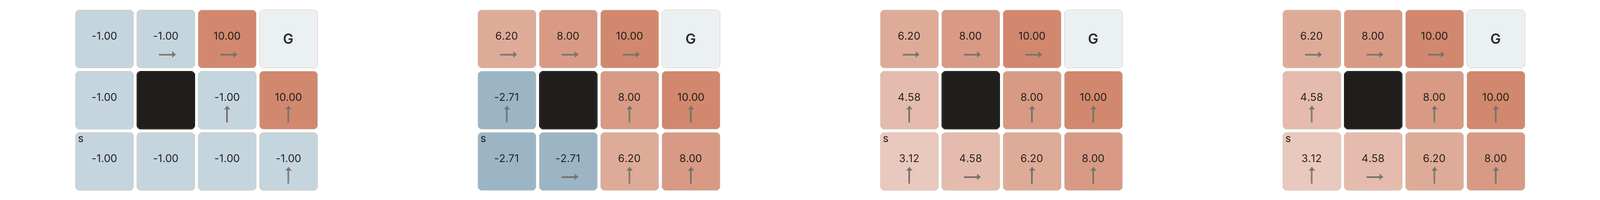

## Q-learning: cập nhật từ một trải nghiệm

Bây giờ agent chỉ gọi `step` cho hành động đã chọn. Nó lưu bảng $Q(s,a)$ shape `(11, 4)`; mỗi hàng là một ô, mỗi cột là một hành động. Sau quan sát $(s,a,r,s')$, target là $r+\gamma\max_{a'}Q(s',a')$. Sai lệch giữa target và giá trị hiện tại được gọi là TD error. Ta cập nhật

$$Q(s,a)\leftarrow Q(s,a)+\alpha\left[r+\gamma\max_{a'}Q(s',a')-Q(s,a)\right].$$

$\alpha$ là learning rate. Viết cách khác, $Q(s,a)\leftarrow(1-\alpha)Q(s,a)+\alpha\cdot\text{target}$: $\alpha=1$ ghi đè bằng target mới nhất, $\alpha$ nhỏ giữ lại phần lớn giá trị cũ và lấy trung bình có trọng số các target đã gặp. Nếu quan sát terminal, target chỉ còn $r$. Ví dụ $Q(s,a)=2$, $r=-1$, giá trị tốt nhất ở trạng thái kế tiếp là 5, $\gamma=0.9$, $\alpha=0.2$: target là $3.5$, TD error là $1.5$, giá trị mới là $2.3$. Nếu đó là bước terminal thưởng 10 thì giá trị mới là $2+0.2(10-2)=3.6$.

**Hỏi nhanh.** Đề chỉ cấp `env.reset()` và `env.step(a)`, trả về trạng thái mới, phần thưởng và cờ kết thúc. Không có bảng chuyển, cũng không có bản đồ. Cách nào chạy được ngay?

- A. Value iteration, vì phương trình Bellman đúng cho mọi MDP
- B. Value iteration, sau khi coi mọi $p(s'\mid s, a)$ bằng nhau
- C. Q-learning trên những transition thu được khi gọi `step`
- D. Dynamic programming theo thứ tự topo của các trạng thái

<details><summary>Đáp án</summary>

C. Q-learning trên những transition thu được khi gọi `step`

Q-learning chỉ cần các bộ $(s, a, r, s')$ thu được khi tương tác. Value iteration cần $p(s', r\mid s, a)$ cho mọi cặp. Coi $p$ đều nhau là giải một MDP khác hẳn. DP theo thứ tự topo cần biết đồ thị và đồ thị phải không có vòng, trong khi ở đây chưa biết đồ thị và lưới lại có vòng. Một hướng khác là ghi lại các transition để ước lượng mô hình, rồi mới lập kế hoạch.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q5.1(iv)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=21)

</details>

Policy lấy hành động có $Q$ lớn nhất có thể bỏ lỡ hướng chưa thử. Ta dùng epsilon-greedy: xác suất $\epsilon$ chọn đều trong cả bốn hành động, còn lại chọn một hành động đạt cực đại. Hành động tốt nhất cũng có thể được chọn trong nhánh ngẫu nhiên. Đây là exploration để thu thông tin về environment; search ở bài 9.2 mở rộng trạng thái bằng quy tắc đã biết. Cả hai có thể cùng xuất hiện trong một hệ thống, nhưng không đồng nghĩa.

In [ ]:
def td_target(reward, next_values, terminated):
    if terminated:
        return reward
    return reward + gamma * np.max(next_values)

assert np.isclose(td_target(-1.0, np.array([5.0, 2.0]), False), 3.5)
# Giá trị cố ý sai ở terminal cũng không được lọt vào target.
assert td_target(10.0, np.full(4, 999.0), True) == 10.0

rng = np.random.default_rng(7)
Q = np.zeros((len(states), 4))
alpha, epsilon = 0.3, 0.2
for episode in range(3000):
    state = start
    for turn in range(100):
        if rng.random() < epsilon:
            action = int(rng.integers(4))
        else:
            best = np.flatnonzero(Q[state] == Q[state].max())
            action = int(rng.choice(best))
        next_state, reward, terminated = step(state, action)
        target = td_target(reward, Q[next_state], terminated)
        Q[state, action] += alpha * (target - Q[state, action])
        state = next_state
        if terminated:
            break

print("Shape bảng Q:", Q.shape)
print(f"Q tốt nhất tại S: {Q[start].max():.3f}")
assert np.all(Q[goal] == 0)

Shape bảng Q: (11, 4)
Q tốt nhất tại S: 3.122


Giới hạn 100 lượt trong code là dừng thu mẫu để chương trình luôn chạy nhanh, không phải terminal của MDP. Ở lượt bị dừng ấy, ta vẫn dùng target có giá trị tương lai, rồi reset để thu một episode mới. Gymnasium trả riêng hai cờ `terminated` và `truncated`; chỉ terminal thật làm mất bootstrap.



**Hỏi nhanh.** Epsilon-greedy có 4 hành động, đúng một hành động tốt nhất, $\epsilon = 0.2$, và nhánh explore chọn đều cả 4 hành động. Xác suất chọn hành động tốt nhất là bao nhiêu?

- A. $0.20$
- B. $0.85$
- C. $0.80$
- D. $0.05$

<details><summary>Đáp án</summary>

B. $0.85$

Nhánh khai thác góp $0.8$. Nhánh explore góp thêm $0.2/4 = 0.05$, vì chọn đều thì vẫn có thể rơi đúng vào hành động tốt nhất. $0.80$ là quên phần đóng góp ấy. $0.05$ chỉ là phần của nhánh explore. $0.20$ là xác suất rơi vào nhánh explore. Nếu explore chỉ chọn trong 3 hành động còn lại thì đáp án mới là $0.80$.

</details>



Mỗi cập nhật chỉ nhìn trước một bước, nên tin tốt ở đích lan ngược về S chậm. Với $\alpha=1$ và $Q$ khởi tạo 0, trong episode đầu tiên tới đích chỉ cặp trạng thái–hành động cuối cùng nhận target có thưởng 10; các cặp trước đó đã được cập nhật khi giá trị phía sau còn bằng 0. Mỗi lần đi lại cùng đường, thông tin lùi thêm một bước. Experience replay lưu các transition đã gặp vào bộ nhớ rồi cập nhật lại nhiều lần, nhờ đó dùng mỗi lần tương tác hiệu quả hơn; đây cũng là một thành phần của DQN, Q-learning với mạng neural.

**Hỏi nhanh.** Episode đầu tiên đi 5 transition từ S tới đích, và tất cả đều được lưu lại. Q-learning với $\alpha = 1$, $Q$ khởi tạo bằng 0. Phát lại 5 transition này theo thứ tự nào để $Q$ tại S đạt $3.122$ chỉ sau một lượt quét?

- A. Đúng thứ tự đã đi, từ S tới đích
- B. Ngẫu nhiên, để các mẫu bớt tương quan
- C. Chỉ transition cuối cùng, lặp lại 5 lần
- D. Ngược từ transition cuối cùng về S

<details><summary>Đáp án</summary>

D. Ngược từ transition cuối cùng về S

Cập nhật ngược thì mỗi cặp dùng giá trị phía sau vừa được tính: $10$, rồi $8$, $6.2$, $4.58$ và $3.122$. Đi xuôi thì lặp lại đúng tình trạng của episode đầu: mọi cặp trước đích chỉ thấy giá trị 0 ở phía sau. Lặp transition cuối không đưa thông tin gì về các ô khác. Xáo trộn có ích khi train mạng, để giảm tương quan giữa các mẫu, nhưng không bảo đảm thưởng lan hết trong một lượt.

</details>



## Đọc policy, không chỉ đọc một ô Q

Con số ở S gần đáp án chuẩn chưa chứng minh robot đi được. Ta tắt exploration, chạy policy greedy và in cả đường đi. Evaluation không cập nhật $Q$; tránh việc kiểm tra cũng làm thay đổi agent.

In [ ]:
state = start
path = [states[state]]
actions_taken, observed_rewards = [], []
for _ in range(30):
    action = int(np.argmax(Q[state]))
    state, reward, terminated = step(state, action)
    actions_taken.append(action_names[action])
    observed_rewards.append(reward)
    path.append(states[state])
    if terminated:
        break

discounted = sum(gamma ** t * r for t, r in enumerate(observed_rewards))
print("Hành động:", " ".join(actions_taken))
print("Đường đi:", path)
print(
    f"Số bước: {len(actions_taken)}, "
    f"return: {discounted:.3f}"
)
assert state == goal and len(actions_taken) == 5
assert np.isclose(discounted, V[start])

Hành động: R R U U R
Đường đi: [(2, 0), (2, 1), (2, 2), (1, 2), (0, 2), (0, 3)]
Số bước: 5, return: 3.122


Nhìn `Số bước` trước: đường ngắn nhất từ S dài 5 bước (đếm trên hình hoặc bằng BFS), nên từ S agent đã đạt mức tối ưu. Lưới có nhiều đường ngắn nhất, vì vậy chuỗi hành động có thể khác mũi tên trong hình mà return vẫn là `3.122`. Một đường đi chỉ kiểm policy tại S; muốn kiểm cả policy, chạy evaluation từ mọi ô và so với $V^*$ của value iteration.

Định lý hội tụ của Q-learning dạng bảng cần mọi cặp trạng thái–hành động được thử vô số lần và learning rate giảm dần thích hợp. Ở lưới tất định của bài, $\alpha=0.3$ cố định đã cho đúng kết quả; khi chuyển trạng thái ngẫu nhiên, $\alpha$ cố định khiến $Q$ luôn dao động theo các mẫu gần nhất.

**Hỏi nhanh.** Một bảng Q mới học 20 episode. Đánh giá greedy từ S cho đường $(2, 0)\to(2, 1)\to(2, 0)\to(2, 1)\to\cdots$ cho đến hết 30 lượt mà không tới đích. Ta kết luận gì, và nên làm gì?

- A. Environment sai, vì policy greedy luôn phải tới được đích
- B. Bật lại $\epsilon = 0.2$ khi đánh giá để robot thoát khỏi vòng lặp
- C. Q chưa học xong ở hai ô này, nên train thêm rồi đánh giá lại
- D. Return bằng 0 vì không tới đích, nên bỏ hẳn lần đánh giá này

<details><summary>Đáp án</summary>

C. Q chưa học xong ở hai ô này, nên train thêm rồi đánh giá lại

Policy greedy theo một bảng Q chưa hội tụ có thể đi vòng, và giới hạn 30 lượt trong phần đánh giá tồn tại chính vì vậy. Bật $\epsilon$ là đo một policy khác, không phải policy sẽ nộp. Không tới đích thì vẫn có return: 30 bước $-1$ cho $-(1 - 0.9^{30})/(1 - 0.9) \approx -9.58$, một con số tệ đáng ghi lại. Trước khi nghi ngờ environment, hãy so với value iteration như khối code phía trên.

</details>

## Policy gradient: học trực tiếp xác suất hành động

Q-learning học bảng giá trị rồi suy ra policy. Một cách khác là đặt tham số cho policy và tăng kỳ vọng return. Để thấy đúng phép toán, ta tạm dùng nhiệm vụ một bước: chọn trái nhận 1 điểm, chọn phải nhận 3 điểm, rồi episode kết thúc. Đây là một bandit, trường hợp đơn giản nhất của tương tác có thưởng; nó không minh họa khó khăn gán công lao qua nhiều bước.

Đặt xác suất đi phải $p=\sigma(\theta)=1/(1+e^{-\theta})$. Kỳ vọng thưởng là $J(\theta)=1(1-p)+3p=1+2p$. Do $\sigma'(\theta)=p(1-p)$,

$$J'(\theta)=2p(1-p).$$

Tại $\theta=0$, $p=0.5$, gradient bằng $0.5$. Gradient **ascent** với $\eta=0.1$ cho $\theta=0.05$, tăng xác suất phải lên khoảng $0.5125$. Dấu cộng khác với gradient descent của loss vì ta muốn tăng thưởng.

Nếu chưa biết thưởng của cả hai hướng, một mẫu REINFORCE dùng $(R-b)\nabla_\theta\log\pi_\theta(A)$ để ước lượng gradient. $b$ là baseline không phụ thuộc vào hành động đang chọn. Với $A\in\{0,1\}$ và xác suất phải là $p$, đạo hàm log-policy là $A-p$. Lấy $b=2$: chọn phải cho $(3-2)(1-p)$; chọn trái cho $(1-2)(-p)$. Kỳ vọng hai trường hợp đúng bằng $2p(1-p)$.

Ta kiểm tính tay trước, rồi dùng 400 mẫu để cập nhật policy.

In [ ]:
def sigmoid(theta):
    return 1.0 / (1.0 + np.exp(-theta))

p0 = sigmoid(0.0)
theta_hand = 0.1 * 2 * p0 * (1 - p0)
print(f"Một bước exact gradient: theta={theta_hand:.4f}, p={sigmoid(theta_hand):.4f}")

rng_policy = np.random.default_rng(11)
theta_policy = 0.0
for _ in range(400):
    probability = sigmoid(theta_policy)
    action = int(rng_policy.random() < probability)
    reward = 3.0 if action else 1.0
    sample_gradient = (reward - 2.0) * (action - probability)
    theta_policy += 0.05 * sample_gradient

p_final = sigmoid(theta_policy)
print(f"Policy sau 400 mẫu: p(phải)={p_final:.4f}, E[R]={1 + 2 * p_final:.4f}")
assert p_final > 0.9

Một bước exact gradient: theta=0.0500, p=0.5125
Policy sau 400 mẫu: p(phải)=0.9641, E[R]=2.9282


`E[R]` ở dòng cuối tính bằng công thức $1+2p$ của bài toán, không phải trung bình các thưởng đã nhận khi huấn luyện. Sau 400 mẫu, $p$ mới tới khoảng $0.96$ vì kỳ vọng gradient $2p(1-p)$ nhỏ dần khi $p$ gần 1: policy càng chắc chắn thì càng học chậm. Trong môi trường lớn, policy là một mạng neural nhận trạng thái và trả xác suất hành động; ít tham số hơn một bảng khổng lồ, nhưng không còn đáp án chính xác để đối chiếu.



Với episode nhiều bước, mỗi thời điểm $t$ dùng return tính từ chính thời điểm đó:

$$\widehat g=\sum_{t}\left(G_t-b(S_t)\right)\nabla_\theta\log\pi_\theta(A_t\mid S_t).$$

Hành động ở bước $t$ không ảnh hưởng tới các thưởng đã nhận trước nó, nên dùng $G_t$ thay cho tổng thưởng cả episode. Baseline không làm lệch kỳ vọng, vì $\mathbb E_{A\sim\pi_\theta}[\nabla_\theta\log\pi_\theta(A\mid s)]=\nabla_\theta\sum_a\pi_\theta(a\mid s)=0$, nhưng làm các mẫu bớt dao động; lựa chọn thường gặp là một ước lượng của $V(S_t)$. Nếu thay $G_t$ bằng $R_{t+1}+\gamma V_\phi(S_{t+1})$, với $V_\phi$ do một mạng thứ hai học, ta được actor-critic: actor là policy, critic là hàm giá trị.

**Hỏi nhanh.** Ta muốn cực đại hóa kỳ vọng thưởng $J(\theta)$, và đã có `gradient` bằng $J'(\theta)$. Dòng cập nhật nào đúng?

- A. `theta += lr * gradient`
- B. `theta -= lr * gradient`
- C. `theta += lr * abs(gradient)`
- D. `theta = lr * gradient`

<details><summary>Đáp án</summary>

A. `theta += lr * gradient`

Gradient chỉ hướng làm $J$ tăng nhanh nhất, nên phải đi theo nó, tức gradient ascent. Dấu trừ dành cho việc cực tiểu hóa loss. Có thể đặt loss bằng $-J$ để dùng optimizer kiểu descent, nhưng phải giữ dấu nhất quán. `abs` làm mất thông tin về hướng: khi $J' < 0$ nó vẫn tăng $\theta$. Gán thẳng `theta = lr * gradient` là quên mất giá trị hiện tại.

</details>

**Hỏi nhanh.** Bandit của bài, với $\theta = 0$ nên $p = 0.5$, và baseline $b = 2$. Mẫu vừa rút chọn **trái** và nhận 1 điểm. Sau một cập nhật REINFORCE như trong code, xác suất chọn phải thay đổi thế nào?

- A. Giảm, vì mẫu chọn trái được cộng một thưởng dương
- B. Giữ nguyên, vì 1 điểm vẫn là thưởng dương
- C. Giảm, vì $A - p$ âm khi chọn trái
- D. Tăng, vì trái thấp hơn baseline nên bị đẩy xuống

<details><summary>Đáp án</summary>

D. Tăng, vì trái thấp hơn baseline nên bị đẩy xuống

$(R - b)(A - p) = (1 - 2)(0 - 0.5) = +0.5$, nên $\theta$ tăng, và xác suất chọn phải tăng. Không có baseline thì thưởng dương 1 sẽ đẩy xác suất chọn trái lên, dù trái là lựa chọn kém hơn. Baseline biến tín hiệu thành “tốt hơn hay kém hơn mức thường gặp”. Chỉ nhìn dấu của $A - p$ là quên dấu của $R - b$.

</details>

## Khi đi thi

- **Đọc environment cho gì.** Có bảng chuyển hoặc quy tắc đầy đủ thì planning (BFS, DP, value iteration) cho đáp án chính xác; chỉ có `reset` và `step` thì phải học từ tương tác. Ghi lại giới hạn số lần gọi `step`, số lượt mỗi episode và thời gian chạy.
- **Kiểm `step` bằng tay trước khi train.** Thử va tường, vào đích, hết lượt; target ở terminal chỉ còn $r$, còn bước bị cắt vì hết lượt vẫn bootstrap.
- **Có quy tắc thì dựng oracle.** BFS hoặc value iteration trên bản nhỏ cho con số để đối chiếu agent; nhiều đề giải xong ngay ở bước này.
- **Đánh giá riêng, greedy, nhiều episode.** Đặt agent ngẫu nhiên làm baseline; không chọn checkpoint bằng thưởng lúc exploration; với môi trường ngẫu nhiên, báo trung bình qua nhiều episode và seed.
- **Câu tính tay: viết rõ quy ước.** Ghi $\gamma$, $\alpha$, thưởng thuộc bước nào và đâu là terminal, rồi cập nhật đúng thứ tự trải nghiệm; bảng Q cập nhật tại chỗ nên giá trị mới được dùng ngay ở bước sau.

## Tóm tắt

- MDP làm rõ trạng thái, hành động, quy luật chuyển và thưởng; trạng thái phải giữ các biến cần cho bước tiếp theo. Thưởng và $\gamma$ quyết định thế nào là tối ưu.
- Return cộng thưởng tương lai với hệ số chiết khấu. Terminal có giá trị tương lai 0 nhưng không xóa thưởng của bước kết thúc; bước bị cắt vì hết lượt vẫn bootstrap.
- Bellman nối giá trị hiện tại với giá trị tương lai. Value iteration dùng mô hình và lan thông tin một bước mỗi vòng; Q-learning cập nhật từ từng transition, có thể tăng tốc bằng replay.
- Exploration thu thêm thông tin; evaluation greedy đo policy đã học. Policy gradient tăng kỳ vọng thưởng bằng cách chỉnh xác suất hành động; baseline giảm dao động mà không đổi kỳ vọng.

## Kiểm tra cuối bài

**Câu 1.** Bốn đội mô tả bài toán cờ của mình. Bài nào là reinforcement learning?

- A. Chương trình tự chơi nhiều ván, chỉ biết thắng hay thua khi ván kết thúc
- B. Có 50 000 thế cờ, mỗi thế kèm nước đi của kiện tướng, và học bắt chước
- C. Có một triệu ván không kèm kết quả, và gom các thế cờ giống nhau thành nhóm
- D. Có ảnh chụp bàn cờ kèm bên thắng, và dự đoán bên thắng cho ảnh mới

<details><summary>Đáp án</summary>

A. Chương trình tự chơi nhiều ván, chỉ biết thắng hay thua khi ván kết thúc

Tự chơi, chọn nước đi, rồi chỉ nhận thưởng hoặc phạt là thắng hay thua ở cuối ván, đúng khung agent, environment và reward. Khó khăn chính là gán công lao cho những nước đi trước đó. Bắt chước kiện tướng là học có giám sát, vì mỗi thế cờ đã có sẵn “nhãn đúng”, dù dữ liệu đến từ trò chơi. Gom thế cờ là học không giám sát. Dự đoán bên thắng từ ảnh là phân loại có nhãn.
Phỏng theo: [NOAI 2025 Singapore · Phần 1 · Câu 3](https://learn.aisingapore.org/wp-content/uploads/2025/10/NOAI-2025-MCQ-Assessment-Questions.pdf#page=1)

</details>

**Câu 2.** Environment bị viết sai: bước vào đích nhận 10 nhưng không kết thúc. Đứng ở đích mà đi lên thì va tường, vẫn ở đích, và lại nhận 10. Với $\gamma = 0.9$, value iteration cho giá trị của ô đích bằng bao nhiêu?

- A. $10$
- B. $19$
- C. $100$
- D. Vô hạn, vì cứ cộng 10 mãi

<details><summary>Đáp án</summary>

C. $100$

Ở đích, hành động tốt nhất là va tường để nhận 10 rồi quay lại chính trạng thái đó, nên $V = 10 + 0.9V$, và $V = 100$. Tổng vô hạn số hạng vẫn hữu hạn, vì hệ số $0.9^t$ giảm dần. $10$ là chỉ tính một lần nhận thưởng. $19$ là cộng thêm đúng một bước. Robot học cách đứng lì ở đích để nhận điểm thay vì hoàn thành nhiệm vụ, và mọi ô khác cũng bị đánh giá quá cao. Cờ `terminated` là một phần của định nghĩa phần thưởng.

</details>

**Câu 3.** Trên lưới của bài, mỗi bước bị $-1$, bước vào đích được $+10$, và $\gamma = 0.9$. Đổi thưởng vào đích thành $0$, các bước khác vẫn $-1$. Policy tối ưu và $V^*(S)$ thay đổi thế nào?

- A. Policy đổi, robot tránh đích, và $V^*(S)$ giảm
- B. Policy đổi, robot đi vòng, và $V^*(S)$ tăng
- C. Policy giữ nguyên, và $V^*(S)$ không đổi
- D. Policy giữ nguyên, còn $V^*(S)$ giảm

<details><summary>Đáp án</summary>

D. Policy giữ nguyên, còn $V^*(S)$ giảm

Mỗi bước chưa tới đích vẫn bị trừ 1, nên tới đích nhanh là cách duy nhất để ngừng mất điểm. Không bao giờ tới đích thì được $-1/(1 - 0.9) = -10$, tệ hơn mọi đường tới đích. Vì vậy policy tối ưu giữ nguyên, chỉ có giá trị thay đổi: $V^*(S) = -1 - 0.9 - 0.9^2 - 0.9^3 + 0.9^4\cdot 0 = -3.439$ thay vì $3.122$. Thưởng dương ở đích không phải điều kiện để robot muốn về đích.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q3.7](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=16)

</details>

**Câu 4.** Mặt sàn trơn. Robot ở ô X, cách đích 2 ô trên một đường thẳng, với ô Y nằm giữa. Lệnh “tiến” có xác suất $0.8$ đi một ô và $0.2$ trượt đi hai ô. Từ Y thì cả hai trường hợp đều vào đích. Vào đích nhận 10, bước khác nhận 0, $\gamma = 0.9$, và “tiến” là hành động tốt nhất. $V^*(X)$ bằng bao nhiêu?

- A. $9.0$
- B. $9.2$
- C. $10$
- D. $11.0$

<details><summary>Đáp án</summary>

B. $9.2$

Từ Y, mọi kết quả đều vào đích, nên $V^*(Y) = 10$. Tại X, lấy kỳ vọng theo các kết quả của **một** hành động: $0.2\cdot 10 + 0.8(0 + 0.9\cdot 10) = 2 + 7.2 = 9.2$. $9.0$ là bỏ qua khả năng trượt. $10$ là coi trường hợp tốt luôn xảy ra. $11.0$ là quên nhân xác suất $0.8$ cho nhánh đi một ô.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q3.9](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=17)

</details>

**Câu 5.** Một policy cố định đưa robot đi qua đi lại mãi giữa hai ô. Từ A sang B nhận 0, từ B sang A nhận 1, và $\gamma = 0.8$. $V^\pi(A)$ bằng bao nhiêu?

- A. $0.8$
- B. $2.222$
- C. $2.778$
- D. $5$

<details><summary>Đáp án</summary>

B. $2.222$

Viết phương trình Bellman cho policy cố định: $V(A) = 0 + 0.8\,V(B)$ và $V(B) = 1 + 0.8\,V(A)$. Thế vào thì $V(A) = 0.8 + 0.64\,V(A)$, nên $V(A) = 0.8/0.36 \approx 2.222$. $2.778$ là $V(B)$. $0.8$ chỉ tính hai bước đầu. $5 = 1/(1 - 0.8)$ là như thể bước nào cũng nhận 1.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q6(a)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=17)

</details>

**Câu 6.** Value iteration lưu $p(s'\mid s, a)$ thành một bảng đầy đủ, với $|\mathcal S| = 2000$ trạng thái và $|\mathcal A| = 5$ hành động. Một vòng cập nhật mọi trạng thái tốn cỡ bao nhiêu phép nhân cộng, và chuyển trạng thái ngẫu nhiên có làm đổi con số ấy không?

- A. Khoảng $2\cdot 10^7$, ngẫu nhiên hay tất định cũng như nhau
- B. Khoảng $2\cdot 10^7$, nhưng ngẫu nhiên làm tăng lên nhiều lần
- C. Khoảng $10^4$, nhưng ngẫu nhiên làm tăng lên $2\cdot 10^7$
- D. Khoảng $8\cdot 10^9$, vì phải giải một hệ cỡ $|\mathcal S|^3$

<details><summary>Đáp án</summary>

A. Khoảng $2\cdot 10^7$, ngẫu nhiên hay tất định cũng như nhau

Mỗi cặp $(s, a)$ cộng qua mọi $s'$ trong bảng, nên có $|\mathcal S|^2|\mathcal A| = 2000^2\cdot 5 = 2\cdot 10^7$ phép, dù nhiều xác suất bằng 0. Bảng đầy đủ không phân biệt chuyển tất định hay ngẫu nhiên, nên chi phí không đổi. $10^4 = |\mathcal S||\mathcal A|$ chỉ đạt được khi lưu riêng danh sách trạng thái kế tiếp, như hàm `step` của bài. $|\mathcal S|^3$ là chi phí giải trực tiếp hệ tuyến tính của $V^\pi$, tức bước đánh giá trong policy iteration, không phải một vòng value iteration.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q4.1](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=18)

</details>

**Câu 7.** MDP có bốn trạng thái A, B, C, D và hai hành động Move, Stay chưa rõ tác dụng. Q-learning với $Q$ khởi tạo bằng 0, $\alpha = 1$, $\gamma = 0.9$ lần lượt nhận các transition $(A, \text{Move}, 0, B)$, $(B, \text{Move}, 0, C)$, $(C, \text{Move}, 1, A)$, $(A, \text{Move}, 0, B)$ và $(B, \text{Move}, 0, C)$. Sau năm lần cập nhật, những ô nào của bảng $Q$ khác 0?

- A. Chỉ có $Q(C, \text{Move}) = 1$
- B. $Q(C, \text{Move}) = 1$, $Q(B, \text{Move}) = 0.9$ và $Q(A, \text{Move}) = 0.81$
- C. $Q(C, \text{Move}) = 1$ và $Q(B, \text{Move}) = 0.9$
- D. $Q(A, \text{Move})$, $Q(B, \text{Move})$ và $Q(C, \text{Move})$ đều bằng 1

<details><summary>Đáp án</summary>

C. $Q(C, \text{Move}) = 1$ và $Q(B, \text{Move}) = 0.9$

Với $\alpha = 1$, mỗi lần cập nhật ghi đè $Q(s, a) = r + 0.9\max_{a'} Q(s', a')$. Ba lần đầu chỉ đặt $Q(C, \text{Move}) = 1$. Lần thứ tư, $Q(A, \text{Move}) = 0.9\cdot 0 = 0$, vì lúc đó B chưa có tin tốt nào. Lần thứ năm, $Q(B, \text{Move}) = 0.9\cdot 1 = 0.9$. Giá trị $0.81$ cho A chỉ xuất hiện ở lần đi qua A **sau** đó, vì thưởng lan ngược mỗi lượt một bước.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q7(a)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=19)

</details>

**Câu 8.** Tiếp tục với bảng $Q$ của câu trước, $\alpha = 1$, $\gamma = 0.9$. Agent nhận thêm $(A, \text{Move}, 0, B)$ rồi $(B, \text{Move}, 0, D)$, và mọi $Q(D, \cdot)$ vẫn bằng 0. Giá trị mới của $Q(A, \text{Move})$ và $Q(B, \text{Move})$ là bao nhiêu, và cần sửa điều gì?

- A. $0.81$ và $0.9$, không cần sửa gì vì bảng Q đã đúng
- B. $0$ và $0$, nên tăng $\gamma$ lên 1 để giữ giá trị ở xa lâu hơn
- C. $0.81$ và $0$, nên tăng $\epsilon$ để thử Stay nhiều hơn ở mọi ô
- D. $0.81$ và $0$, nên giảm $\alpha$ để lấy trung bình các lần thử

<details><summary>Đáp án</summary>

D. $0.81$ và $0$, nên giảm $\alpha$ để lấy trung bình các lần thử

$Q(A, \text{Move}) = 0.9\cdot 0.9 = 0.81$, còn $Q(B, \text{Move}) = 0 + 0.9\cdot 0 = 0$. Move ở B lúc thì tới C, lúc thì tới D, tức chuyển trạng thái là ngẫu nhiên. Với $\alpha = 1$, mỗi mẫu mới xóa sạch kinh nghiệm cũ, nên $Q$ nhảy từ $0.9$ về $0$. $\alpha$ nhỏ, hoặc giảm dần, làm $Q$ tiến dần tới kỳ vọng của target. Thử Stay nhiều hơn không sửa được việc ghi đè. $\gamma$ không liên quan đến dao động này.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q7(c)–(d)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=20)

</details>

**Câu 9.** Environment cắt mỗi episode ở lượt 100, với `truncated=True`, dù robot chưa tới đích. Đoạn cập nhật dưới đây sai ở đâu?
```py
s2, r, terminated, truncated, _ = env.step(a)
done = terminated or truncated
target = r if done else r + gamma * Q[s2].max()
Q[s, a] += alpha * (target - Q[s, a])
```

- A. Không sai, vì episode đã dừng thì tương lai bằng 0
- B. Phải đặt `r = 0` ở bước bị cắt
- C. Target phải dùng `terminated`, còn `done` chỉ dùng để reset
- D. Target phải dùng `truncated`, còn `terminated` chỉ dùng để reset

<details><summary>Đáp án</summary>

C. Target phải dùng `terminated`, còn `done` chỉ dùng để reset

Hết lượt là giới hạn của việc thu mẫu, không phải nhiệm vụ đã kết thúc. `s2` vẫn có tương lai, nên target vẫn phải bootstrap. Dùng `done` là cắt mất phần $\gamma\max Q$, kéo $Q$ của những ô hay gặp ở lượt 100 xuống thấp hơn thật. Đặt `r = 0` là sửa sai chỗ, vì thưởng $-1$ của bước ấy vẫn có thật. Đảo vai trò của hai cờ thì lại bootstrap qua đích thật.

</details>

**Câu 10.** Với bandit của bài, trái được 1 điểm, phải được 3 điểm, $p = 0.5$, và mẫu REINFORCE là $(R - b)(A - p)$. So sánh baseline $b = 0$ với $b = 2$.

- A. Cùng kỳ vọng $0.5$, phương sai là $1$ với $b = 0$ và $0$ với $b = 2$
- B. Cùng kỳ vọng $0.5$, cùng phương sai $1$ với cả hai baseline
- C. Kỳ vọng $1.5$ với $b = 0$ và $0.5$ với $b = 2$, cùng phương sai
- D. Kỳ vọng $0.5$ với $b = 0$ và $0$ với $b = 2$, phương sai đều bằng $0$

<details><summary>Đáp án</summary>

A. Cùng kỳ vọng $0.5$, phương sai là $1$ với $b = 0$ và $0$ với $b = 2$

Với $b = 0$, chọn phải được $3\cdot 0.5 = 1.5$, chọn trái được $1\cdot(-0.5) = -0.5$, nên trung bình là $0.5$ và phương sai là $1$. Với $b = 2$, chọn phải được $1\cdot 0.5 = 0.5$, chọn trái được $(-1)(-0.5) = 0.5$, nên mọi mẫu đều bằng $0.5$, và phương sai bằng $0$. Kỳ vọng không đổi vì $\mathbb E[A - p] = 0$, nên baseline chỉ làm bớt dao động. Ở đây $b = 2$ đúng bằng thưởng trung bình, nên triệt tiêu hết nhiễu. Trong những bài nhiều bước, một baseline tốt thường là ước lượng của $V(S_t)$.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q5.3(a)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=25)

</details>

## Đọc thêm

- Sutton, Barto — [*Reinforcement Learning: An Introduction*, bản thứ hai](https://incompleteideas.net/book/the-book-2nd.html), chương 3, 4, 6 và 13. Đọc định nghĩa MDP, Bellman, Q-learning và REINFORCE; chú ý các giả thiết của kết quả hội tụ.
- Ma, Ng — [*CS229 Lecture Notes*, phần Reinforcement Learning and Control](https://cs229.stanford.edu/main_notes.pdf). Đọc để nối Bellman và value iteration với dynamic programming và phân biệt mô hình đã biết với học từ tương tác.
- Watkins, Dayan — [*Q-learning*](https://www.gatsby.ucl.ac.uk/~dayan/papers/cjch.pdf), 1992. Đọc định nghĩa cập nhật bản bảng và các điều kiện của kết quả hội tụ; một lưới nhỏ chạy đúng không thay được những điều kiện ấy.
- Sutton và cộng sự — [*Policy Gradient Methods for Reinforcement Learning with Function Approximation*](https://papers.nips.cc/paper/1999/hash/464d828b85b0bed98e80ade0a5c43b0f-Abstract.html). Đọc sau ví dụ bandit để thấy vì sao có thể ước lượng gradient của một policy từ trải nghiệm.
- [Gymnasium — Handling Time Limits](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/). Đọc để xử lý đúng `terminated`, `truncated` và bootstrap khi chuyển code của bài sang environment thư viện.